# 10 · Fugas

**Objetivo (RF-002.2):** detectar las fugas de la red con el caudal que entrega la fuente y la
presión de los sensores, distinguirlas de las variaciones normales de la operación y decir en qué
tramo de la red están.

**Cómo se mide** (por episodio, como el detector del notebook 07):

| Métrica | Qué significa |
|---|---|
| fugas detectadas | fugas (desde que el tubo se rompe hasta que se repara) con alarma en alguna de esas horas |
| falsas alarmas por semana | episodios de alarma que no tocan ninguna hora con fuga abierta |
| precisión, sensibilidad y F1 por evento | alarmas que eran fuga, fugas detectadas y su promedio (RNF-003, meta ≥ 80 %) |
| retraso | horas desde que el tubo se rompe hasta la primera alarma |
| tramo correcto | el tramo dicho (entre qué dos sensores) es el de la fuga |

**Diseño** (`calidad_agua/fugas.py`):

1. **Lo esperado en operación normal.** El caudal y la presión suben y bajan con la hora del día,
   el fin de semana, la época del año, el calor y la lluvia, y con los arranques de bombas. Una
   **regresión multivariable** por señal (caudal de la fuente y presión de cada sensor), ajustada
   con horas sin fuga del entrenamiento, y una **línea base de la semana** (la mediana de la misma
   hora en los 7 días anteriores) dan lo esperado; el **residuo** es lo que la operación normal no
   explica.
2. **Tres modelos con esos residuos**, como pide el RF-002.2: **Random Forest** y **SVM**
   (supervisados, con las etiquetas de fuga) y **Autoencoder** (TensorFlow/Keras, sin etiquetas:
   aprende a reconstruir la operación normal y marca lo que no puede reconstruir; umbral en el
   **percentil 95** del error en la operación normal).
3. **Umbral y horas de confirmación** con validación por bloques y la misma regla de los otros
   notebooks, fijada antes de ver resultados: máximo de fugas detectadas con a lo sumo 1 falsa
   alarma por semana en cada bloque.
4. **Tramo:** con 3 puntos de medición no se ubica una fuga al metro, pero sí entre qué dos
   sensores está (los dos más cercanos por tubería al punto de la fuga). Un Random Forest lo
   aprende del patrón de residuos; la línea base es "los dos sensores donde más bajó la presión".

Anticipar las fugas que empiezan pequeñas y crecen (24 h antes de que el tubo se rompa) se hace en
el notebook 09, con los demás tipos de evento.

In [1]:
import sys, time
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))          # por si calidad_agua no está instalado (pip install -e .)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import joblib
from sklearn.metrics import mean_absolute_error, r2_score

from calidad_agua import carga, calidad, configuracion, detector, experimentos
from calidad_agua import fugas as F
from calidad_agua.eventos import episodios
from calidad_agua.graficos import estilo, guardar, COLORES, GRIS

estilo()
pd.set_option("display.precision", 2)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

crudo = carga.cargar_todo()
t15 = calidad.lecturas_operativas(crudo)
h = detector.horario(t15)                     # promedios horarios, eventos por sensor y partición
S = carga.sensores(h)
cat = carga.catalogo_eventos()
cat_f = cat[cat["tipo"] == "fuga"].copy()
y = F.clase(h, cat)                 # 1 mientras hay una fuga abierta (del catálogo)
PERIODO = {p: carga.periodos()[p] for p in carga.PARTICIONES}
entr = (h["particion"] == "entrenamiento").values
val = (h["particion"] == "validacion").values
prueba = (h["particion"] == "prueba").values

# horas "normales" para la regresión: sin fuga y lejos de una fuga (ni la fuga pequeña que
# crece antes, ni las 12 h después de repararla, mientras los tanques se recuperan)
cerca = np.zeros(len(h), bool)
for _, ev in cat_f.iterrows():
    cerca |= (h.index >= ev["inicio_precursor"]) & (h.index < ev["fin"] + pd.Timedelta(hours=12))
normal = ~cerca & (y.values == 0)

mods_normal = F.ajustar_normal(h, entr & normal)
X = F.tabla(h, mods_normal)
COL = list(X.columns)
TRAMO = F.tramos(carga.distancias_sensores())
cat_f["tramo"] = cat_f["ubicacion"].map(TRAMO)

vis = episodios(y)
vis["partición"] = h.loc[vis["inicio"], "particion"].values
print(f"Sensores del sistema: {S} · {len(COL)} variables")
cat_f["partición"] = h["particion"].reindex(cat_f["inicio"].dt.floor("h")).values
cat_f.groupby("partición").agg(fugas=("id", "size"), caudal_mediano_Ls=("intensidad", "median"),
                               horas_medianas=("duracion_h", "median"),
                               empiezan_pequeñas=("causa", lambda c: int((c == "deterioro_gradual").sum()))) \
     .reindex(carga.PARTICIONES)

Sensores del sistema: ['J280', 'J224', 'J237'] · 46 variables


,fugas,caudal_mediano_Ls,horas_medianas,empiezan_pequeñas
partición,,,,
entrenamiento,34,17.00,26.5,19
validacion,14,22.15,20.0,8
prueba,8,15.15,25.5,4


In [2]:
reg = experimentos.iniciar("fugas", "10 · fugas", "10_fugas")
reg.parametros({"sensores": ", ".join(S), "variables_entrada": len(COL)})

## 1. Lo normal y lo que deja una fuga

Qué tan bien explica la regresión el caudal y la presión en horas normales de la validación (que
no se usaron para ajustarla), y cómo se ve en promedio una fuga en los residuos contra la semana:
las horas antes y después de que el tubo se rompe (antes, en la mitad de los casos, ya hay una
fuga pequeña que crece).

In [3]:
Xr, Y = F._regresores(h), F.senales(h)
filas = {}
for c in Y.columns:
    m = val & normal & Y[c].notna().values
    pred = mods_normal[c].predict(Xr.values[m])
    filas[c] = {"R² (validación, horas normales)": r2_score(Y[c].values[m], pred),
                "error medio absoluto": mean_absolute_error(Y[c].values[m], pred),
                "desviación del residuo": float(np.std(Y[c].values[m] - pred))}
calidad_regresion = pd.DataFrame(filas).T
reg.tabla(calidad_regresion.reset_index(), "regresion_normal")
calidad_regresion

,"R² (validación, horas normales)",error medio absoluto,desviación del residuo
caudal,4.26e-01,14.14,14.03
presion_J280,3.07e-03,0.08,0.10
presion_J224,6.39e-01,0.51,0.62
presion_J237,5.09e-01,2.23,3.67


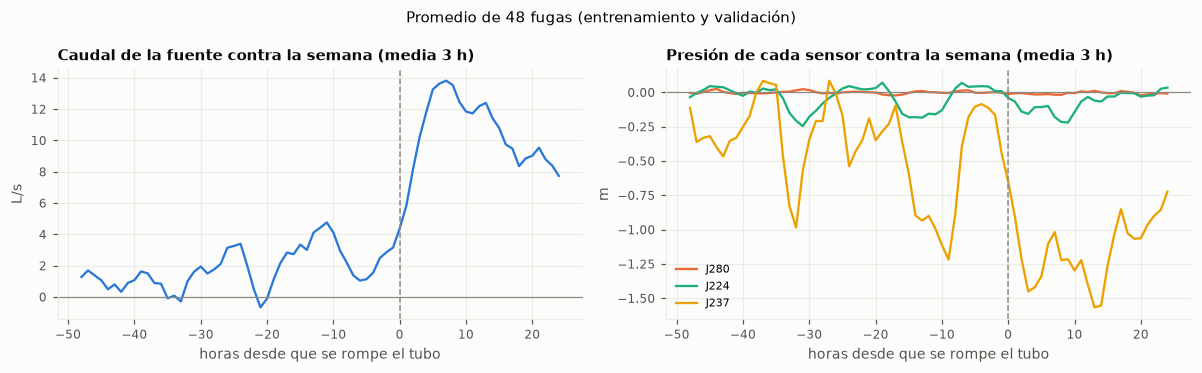

In [4]:
ventana = range(-48, 25)
dec = vis[vis["partición"] != "prueba"]
perfiles = {}
for c in ["caudal"] + [f"presion_{n}" for n in S]:
    serie = X[f"{c}_vs_semana_media3h"]
    perfiles[c] = pd.Series({k: np.nanmean([serie.get(ini + pd.Timedelta(hours=k), np.nan) for ini in dec["inicio"]])
                             for k in ventana})
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
axes[0].plot(perfiles["caudal"], color=COLORES[0])
axes[0].set_ylabel("L/s"); axes[0].set_title("Caudal de la fuente contra la semana (media 3 h)", fontsize=10)
for k, n in enumerate(S):
    axes[1].plot(perfiles[f"presion_{n}"], color=COLORES[k + 1], label=n)
axes[1].set_ylabel("m"); axes[1].set_title("Presión de cada sensor contra la semana (media 3 h)", fontsize=10)
axes[1].legend(fontsize=7)
for a in axes:
    a.axvline(0, color=GRIS, ls="--", lw=1); a.axhline(0, color=GRIS, lw=0.8)
    a.set_xlabel("horas desde que se rompe el tubo")
fig.suptitle(f"Promedio de {len(dec)} fugas (entrenamiento y validación)", fontsize=10)
fig.tight_layout()
guardar(fig, "10_perfil_fuga"); plt.show()

## 2. Tres modelos y su umbral (validación por bloques)

Igual que en los notebooks 07 y 09: el entrenamiento se parte en cuatro bloques de 4 meses y, para
cada uno, se ajustan la regresión y los modelos con el resto y se evalúa en ese bloque; la
validación oficial es el quinto bloque. Con las probabilidades de los cinco bloques se elige, para
cada modelo, el umbral y las horas de confirmación con la regla fijada de antemano: **máximo de
fugas detectadas con a lo sumo 1 falsa alarma por semana en cada bloque**; a igualdad, menos
falsas y menos retraso. En el Autoencoder el umbral está en veces el percentil 95 del error normal
(1 = el percentil 95, el umbral que fija el RF-002.2).

La prueba no se usa para decidir.

In [5]:
BLOQUES = {"sep–dic 2024": ("2024-09-01", "2025-01-01"), "ene–abr 2025": ("2025-01-01", "2025-05-01"),
           "may–ago 2025": ("2025-05-01", "2025-09-01"), "sep–dic 2025": ("2025-09-01", "2026-01-01"),
           "validación": tuple(str(f) for f in PERIODO["validacion"])}
ELECCION = F.HIPERPARAMETROS["eleccion"]
MODELOS = {"Random Forest": lambda X_, y_, n_: F.entrenar_bosque(X_, y_),
           "SVM": lambda X_, y_, n_: F.entrenar_svm(X_, y_),
           "Autoencoder": lambda X_, y_, n_: F.Autoencoder().fit(X_[n_])}
p_bloques = {m: pd.Series(np.nan, index=h.index) for m in MODELOS}
segundos = {m: 0.0 for m in MODELOS}
for nombre, (desde, hasta) in BLOQUES.items():
    en_bloque = (h.index >= desde) & (h.index < hasta)
    base = entr & ~en_bloque
    mods_b = F.ajustar_normal(h, base & normal)
    X_b = F.tabla(h, mods_b)
    for m, entrenar in MODELOS.items():
        t0 = time.time()
        mod_b = entrenar(X_b[base], y.values[base], (normal[base]))
        segundos[m] += time.time() - t0
        p_bloques[m][en_bloque] = F.probabilidad(mod_b, X_b[en_bloque])
    print(f"{nombre}: listo")
bloques = [(pd.Timestamp(a), pd.Timestamp(b)) for a, b in BLOQUES.values()]
en_bloques = np.zeros(len(h), bool)
for a, b in bloques:
    en_bloques |= (h.index >= a) & (h.index < b)

sep–dic 2024: listo


ene–abr 2025: listo


may–ago 2025: listo


sep–dic 2025: listo


validación: listo


In [6]:
eleccion, grillas, filas = {}, {}, []
for m in MODELOS:
    umbrales = ELECCION["umbrales_autoencoder"] if m == "Autoencoder" else ELECCION["umbrales"]
    p = p_bloques[m].fillna(0).values
    eleccion[m], grillas[m] = F.elegir_umbral(h.index, p, y.values, bloques, umbrales,
                                              ELECCION["confirmaciones_h"], ELECCION["max_falsas_por_semana"])
    u, c = eleccion[m]
    rs = [F.evaluar(h.index, F.alarma(p, u, c), y.values, a, b)[1] for a, b in bloques]
    det, n, fal, al = (sum(r[k] for r in rs) for k in ["detectadas", "fugas", "falsas", "alarmas"])
    semanas = en_bloques.sum() / (24 * 7)
    prec, sens = (al - fal) / al if al else np.nan, det / n
    filas.append({"modelo": m, "umbral": u, "confirmación (h)": c, "detectadas": det, "de": n,
                  "% detectadas": 100 * sens, "falsas por semana": fal / semanas,
                  "peor bloque (falsas/semana)": max(r["falsas_por_semana"] for r in rs),
                  "precisión %": 100 * prec, "F1 %": 100 * 2 * prec * sens / (prec + sens) if al else 0,
                  "entrenar (s, 5 bloques)": segundos[m]})
# el percentil 95 del Autoencoder sin ajustar (umbral 1, 1 h), como lo fija el RF-002.2
p_ae = p_bloques["Autoencoder"].fillna(0).values
rs = [F.evaluar(h.index, F.alarma(p_ae, 1.0, 1), y.values, a, b)[1] for a, b in bloques]
al, fal, det = sum(r["alarmas"] for r in rs), sum(r["falsas"] for r in rs), sum(r["detectadas"] for r in rs)
filas.append({"modelo": "Autoencoder, percentil 95 sin ajustar", "umbral": 1.0, "confirmación (h)": 1,
              "detectadas": det, "de": n, "% detectadas": 100 * det / n,
              "falsas por semana": fal / semanas, "peor bloque (falsas/semana)": max(r["falsas_por_semana"] for r in rs),
              "precisión %": 100 * (al - fal) / al if al else np.nan,
              "F1 %": 100 * 2 * ((al - fal) / al) * (det / n) / ((al - fal) / al + det / n) if al and det else 0,
              "entrenar (s, 5 bloques)": segundos["Autoencoder"]})
comparacion_bloques = pd.DataFrame(filas).set_index("modelo")
# el modelo elegido: el que detecta más dentro del límite; a igualdad, mayor F1
validos = comparacion_bloques.drop(index="Autoencoder, percentil 95 sin ajustar")
validos = validos[validos["peor bloque (falsas/semana)"] <= ELECCION["max_falsas_por_semana"]] \
    if (validos["peor bloque (falsas/semana)"] <= ELECCION["max_falsas_por_semana"]).any() else validos
ELEGIDO = validos.sort_values(["detectadas", "F1 %"], ascending=False).index[0]
UMBRAL, CONFIRMAR = eleccion[ELEGIDO]
print(f"Modelo elegido: {ELEGIDO}, umbral {UMBRAL:g}, confirmación {CONFIRMAR} h")
reg.parametros({"modelo": ELEGIDO, "umbral": UMBRAL, "confirmacion_h": CONFIRMAR}, "elegido")
reg.tabla(comparacion_bloques.reset_index(), "comparacion_bloques")
comparacion_bloques

Modelo elegido: Random Forest, umbral 0.5, confirmación 3 h


,umbral,confirmación (h),detectadas,de,% detectadas,falsas por semana,peor bloque (falsas/semana),precisión %,F1 %,"entrenar (s, 5 bloques)"
modelo,,,,,,,,,,
Random Forest,0.5,3,37,48,77.08,0.59,0.93,51.43,61.70,4.37
SVM,0.3,3,35,48,72.92,0.33,0.75,66.67,69.65,20.45
Autoencoder,3.0,1,7,48,14.58,0.21,0.76,40.00,21.37,27.85
"Autoencoder, percentil 95 sin ajustar",1.0,1,43,48,89.58,5.33,8.46,14.76,25.34,27.85


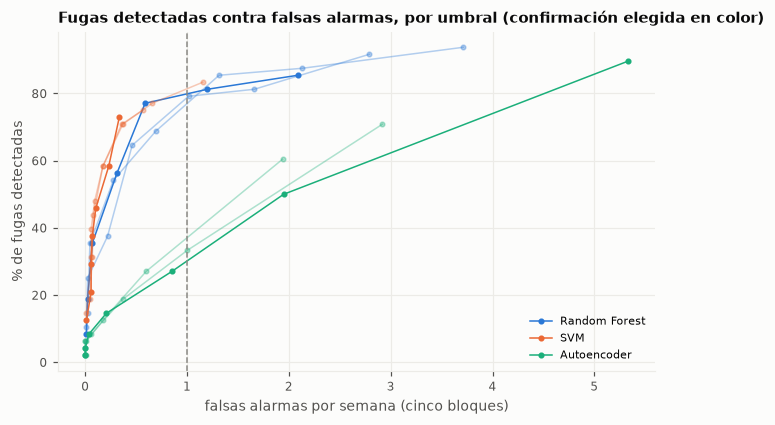

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for k, m in enumerate(MODELOS):
    g = grillas[m]
    g = g.assign(semanas=en_bloques.sum() / (24 * 7))
    for c in ELECCION["confirmaciones_h"]:
        gg = g[g["confirmacion_h"] == c]
        ax.plot(gg["falsas"] / gg["semanas"], 100 * gg["detectadas"] / gg["fugas"], "o-", ms=3, lw=1,
                color=COLORES[k], alpha=1 if c == eleccion[m][1] else 0.35,
                label=f"{m}" if c == eleccion[m][1] else None)
ax.axvline(ELECCION["max_falsas_por_semana"], color=GRIS, ls="--", lw=1)
ax.set_xlabel("falsas alarmas por semana (cinco bloques)"); ax.set_ylabel("% de fugas detectadas")
ax.set_title("Fugas detectadas contra falsas alarmas, por umbral (confirmación elegida en color)", fontsize=10)
ax.legend(fontsize=7)
guardar(fig, "10_umbral"); plt.show()

## 3. Evaluación final en el periodo de prueba

Los tres modelos se entrenan con todo el entrenamiento, con su umbral y confirmación elegidos, y se
evalúan una sola vez en la prueba.

In [8]:
finales, filas, eventos_prueba = {}, [], {}
desde, hasta = PERIODO["prueba"]
for m, entrenar in MODELOS.items():
    t0 = time.time()
    finales[m] = entrenar(X[entr], y.values[entr], normal[entr])
    p = F.probabilidad(finales[m], X)
    u, c = eleccion[m]
    ev, r = F.evaluar(h.index, F.alarma(p, u, c), y.values, desde, hasta)
    eventos_prueba[m] = ev.assign(p=[p[(h.index >= a) & (h.index <= b)].max() for a, b in zip(ev.inicio, ev.fin)])
    filas.append({"modelo": m, **r, "segundos": time.time() - t0})
    with reg.hija(f"10 · {m}") as hija:
        hija.parametros({"umbral": u, "confirmacion_h": c})
        hija.metricas({k: v for k, v in r.items() if np.isscalar(v) and not pd.isna(v)}, "prueba")
prueba_modelos = pd.DataFrame(filas).set_index("modelo")
for k in ["precision", "sensibilidad", "f1"]:
    prueba_modelos[k] = 100 * prueba_modelos[k]
reg.metricas({k: v for k, v in prueba_modelos.loc[ELEGIDO].items() if not pd.isna(v)}, "prueba")
reg.tabla(prueba_modelos.reset_index(), "prueba_modelos")
display(prueba_modelos.rename(columns={"precision": "precisión %", "sensibilidad": "sensibilidad %", "f1": "F1 %"}))
# ¿desde qué tamaño se detectan? (modelo elegido, fugas de la prueba)
ev_e = eventos_prueba[ELEGIDO].merge(cat_f[["inicio", "intensidad", "causa"]].assign(inicio=cat_f["inicio"].dt.floor("h")),
                                     on="inicio", how="left")
ev_e["tamaño"] = pd.cut(ev_e["intensidad"], [0, 10, 20, 40], labels=["5–10 L/s", "10–20 L/s", "20–30 L/s"])
por_tamano = ev_e.groupby("tamaño", observed=False).agg(fugas=("detectado", "size"), detectadas=("detectado", "sum"),
                                                        retraso_mediano_h=("retraso_h", "median"))
reg.tabla(por_tamano.reset_index(), "prueba_por_tamano")
por_tamano

,fugas,detectadas,alarmas,falsas,falsas_por_semana,precisión %,sensibilidad %,F1 %,retraso_mediano_h,segundos
modelo,,,,,,,,,,
Random Forest,9,6,9,3,0.17,66.67,66.67,66.67,15.5,1.19
SVM,9,5,10,4,0.23,60.00,55.56,57.69,9.0,10.96
Autoencoder,9,1,1,0,0.00,100.00,11.11,20.00,8.0,5.55


,fugas,detectadas,retraso_mediano_h
tamaño,,,
5–10 L/s,2,1,29.0
10–20 L/s,3,1,26.0
20–30 L/s,3,3,12.0


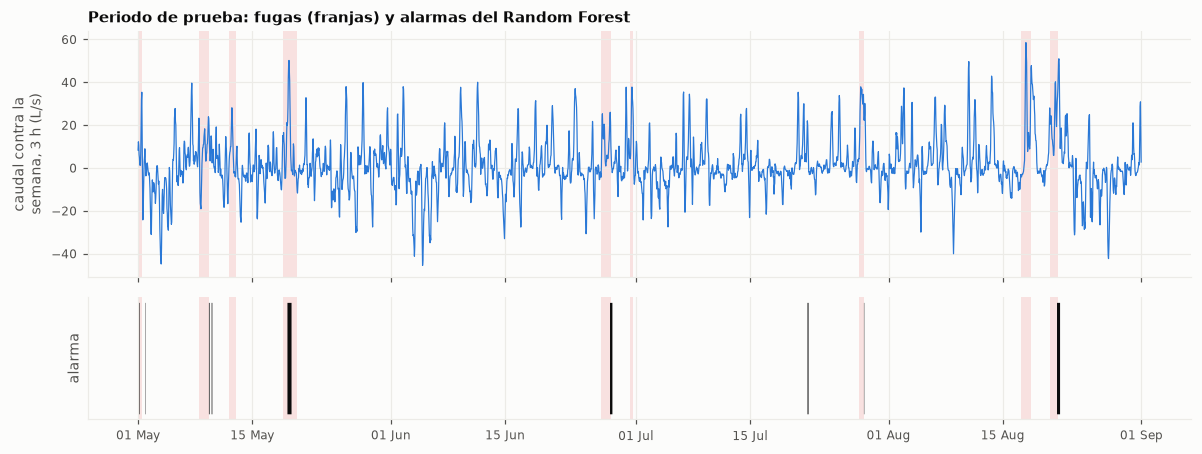

In [9]:
p_final = F.probabilidad(finales[ELEGIDO], X)
alarma_final = pd.Series(F.alarma(p_final, UMBRAL, CONFIRMAR), index=h.index)
tramo_p = slice(desde, hasta - pd.Timedelta(hours=1))
fig, axes = plt.subplots(2, 1, figsize=(11, 4.2), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(X.loc[tramo_p, "caudal_vs_semana_media3h"], color=COLORES[0], lw=0.8)
axes[0].set_ylabel("caudal contra la\nsemana, 3 h (L/s)")
for _, e in episodios(y.loc[tramo_p]).iterrows():
    for a in axes:
        a.axvspan(e.inicio, e.fin + pd.Timedelta(hours=1), color=COLORES[7], alpha=0.15, lw=0)
axes[1].fill_between(alarma_final.loc[tramo_p].index, 0, alarma_final.loc[tramo_p].astype(int), step="post",
                     color="#0b0b0b", lw=0)
axes[1].set_yticks([]); axes[1].set_ylabel("alarma")
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
axes[0].set_title(f"Periodo de prueba: fugas (franjas) y alarmas del {ELEGIDO}", fontsize=10)
fig.tight_layout()
guardar(fig, "10_linea_tiempo_prueba"); plt.show()

## 4. En qué tramo está la fuga

Cada fuga del catálogo se asigna al tramo entre los dos sensores más cercanos por tubería a su
punto (`calidad_agua/fugas.tramos`, con las distancias del simulador). Un Random Forest aprende el
tramo con las horas de fuga del entrenamiento; para cada fuga de la prueba se promedian sus
probabilidades en sus horas. La línea base es la regla "los dos sensores
donde más bajó la presión".

In [10]:
# tramo de cada hora con fuga (la fuga del catálogo que está abierta en esa hora)
tramo_hora = pd.Series(np.nan, index=h.index, dtype=object)
for _, ev in cat_f.iterrows():
    m = (h.index >= ev["inicio"].floor("h")) & (h.index <= ev["fin"]) & (y.values == 1)
    tramo_hora[m] = ev["tramo"]
con_tramo = tramo_hora.notna().values
mod_tramo = F.entrenar_tramo(X[entr & con_tramo], tramo_hora[entr & con_tramo].values)
filas = []
for _, ev in cat_f[(cat_f["inicio"] >= desde) & (cat_f["inicio"] < hasta)].iterrows():
    horas = h.index[(h.index >= ev["inicio"].floor("h")) & (h.index <= ev["fin"]) & (y.values == 1)]
    if len(horas) == 0:
        continue
    dicho, prob = F.tramo_por_evento(mod_tramo, X, horas)
    filas.append({"inicio": ev["inicio"], "nodo": ev["ubicacion"], "L/s": ev["intensidad"], "tramo real": ev["tramo"],
                  "tramo dicho": dicho, "probabilidad": prob, "regla": F.tramo_por_regla(X, S, horas)})
tramos_prueba = pd.DataFrame(filas)
acierto = (tramos_prueba["tramo real"] == tramos_prueba["tramo dicho"]).mean()
acierto_regla = (tramos_prueba["tramo real"] == tramos_prueba["regla"]).mean()
print(f"Tramo correcto: {100 * acierto:.0f} % con el modelo, {100 * acierto_regla:.0f} % con la regla "
      f"({len(tramos_prueba)} fugas en la prueba)")
print("Tramos en el entrenamiento:", tramo_hora[entr].value_counts().to_dict())
reg.metricas({"acierto_tramo": acierto, "acierto_tramo_regla": acierto_regla}, "prueba")
reg.tabla(tramos_prueba, "tramos_prueba")
tramos_prueba

Tramo correcto: 62 % con el modelo, 12 % con la regla (8 fugas en la prueba)
Tramos en el entrenamiento: {'J280 – J237': 669, 'J224 – J237': 277}


,inicio,nodo,L/s,tramo real,tramo dicho,probabilidad,regla
0,2026-05-08 10:00:00,J179,10.0,J280 – J237,J280 – J237,0.52,J280 – J224
1,2026-05-12 04:00:00,J154,6.6,J280 – J237,J280 – J237,0.58,J224 – J237
2,2026-05-18 18:00:00,J26,26.0,J224 – J237,J280 – J237,0.63,J280 – J237
3,2026-06-26 17:00:00,J52,16.7,J280 – J237,J280 – J237,0.63,J280 – J224
4,2026-06-30 07:00:00,J145,13.6,J224 – J237,J224 – J237,0.55,J280 – J224
5,2026-07-28 10:00:00,J350,25.9,J224 – J237,J280 – J237,0.75,J280 – J224
6,2026-08-17 05:00:00,J28,12.2,J224 – J237,J280 – J237,0.53,J224 – J237
7,2026-08-20 19:00:00,J498,24.0,J224 – J237,J224 – J237,0.56,J280 – J237


## 5. Modelo para el servicio

Se guardan la regresión de la operación normal, el modelo elegido con su umbral y confirmación y
el modelo de tramos. Si el elegido es el Autoencoder, la red se guarda aparte en formato Keras.

In [11]:
carpeta = Path.cwd().parent / "modelos"
carpeta.mkdir(exist_ok=True)
modelo = finales[ELEGIDO]
paquete = {"nombre": ELEGIDO, "modelo": modelo, "columnas": COL, "normal": mods_normal, "umbral": UMBRAL,
           "confirmar_h": CONFIRMAR, "tramo": mod_tramo, "tramos": TRAMO.to_dict(), "sensores": S,
           "mlflow": reg.referencia()}
if isinstance(modelo, F.Autoencoder):
    modelo.red_.save(carpeta / "fugas_autoencoder.keras")
    red, modelo.red_ = modelo.red_, None
    joblib.dump(paquete, carpeta / "fugas.joblib", compress=3)
    modelo.red_ = red
    reg.archivo(carpeta / "fugas_autoencoder.keras")
else:
    joblib.dump(paquete, carpeta / "fugas.joblib", compress=3)
print(f"Guardado: modelos/fugas.joblib ({(carpeta / 'fugas.joblib').stat().st_size / 1e6:.1f} MB)")
reg.archivo(carpeta / "fugas.joblib")
reg.figuras_guardadas("10_")
reg.terminar()
print(f"Registrado en MLflow: experimento fugas, corrida {reg.id}")

Guardado: modelos/fugas.joblib (5.5 MB)
Registrado en MLflow: experimento fugas, corrida e25d67bdcec54c88bfff2541d8980a23


## 6. Conclusiones

**Resultado en el periodo de prueba (may–ago 2026)**, con el Random Forest (elegido en la validación
por bloques), umbral 0,5 y 3 h de confirmación:

| | Resultado |
|---|---|
| Fugas detectadas | **6 de 9** |
| Roturas de 20 a 30 L/s | 3 de 3 (12 h después de romperse, mediana) |
| Roturas de 10 a 20 L/s | 1 de 3 |
| Roturas de 5 a 10 L/s | 1 de 2 |
| Falsas alarmas | **0,17 por semana** (3 en 4 meses) |
| Precisión, sensibilidad y F1 por evento | 67 %, 67 % y **67 %** (RNF-003: meta ≥ 80 %) |
| Retraso mediano | 15,5 h desde que se rompe el tubo |
| Tramo correcto | **5 de 8** (62 %); la regla "donde más bajó la presión", 1 de 8 |

En la validación por bloques (20 meses, 48 fugas) el bosque detecta **37 de 48 (77 %)** con 0,59
falsas alarmas por semana (0,93 en el peor bloque).

**Lo que muestran los datos**

1. **El caudal de la fuente lo mandan las bombas y los tanques, no solo el consumo.** La regresión
   de la operación normal explica apenas el 43 % del caudal (R² en validación) y deja un residuo de
   ±14 L/s; en la presión de J224 y J237 explica entre la mitad y dos tercios. Por eso la línea base
   de la semana (la misma hora de los 7 días anteriores) aporta: sigue sola la época del año y los
   cambios lentos de consumo.
2. **Lo que se detecta depende del tamaño de la fuga.** Las roturas grandes (20–30 L/s, más del 7 %
   de lo que entrega la fuente) se detectan todas; las medianas y pequeñas, la mitad o menos. Con
   el dataset anterior (v5), con fugas de 2 a 10 L/s (1–4 % del caudal), ningún modelo las separaba
   del ruido (AUC por hora de 0,70): el consumo varía solo un 3 % de hora en hora, y con un
   caudalímetro y dos puntos de presión esas fugas no se distinguen.
3. **La detección no es inmediata.** Comparar con la semana y pedir 3 h de confirmación cuesta
   horas: la alarma llega en mediana 12 a 15 h después de la rotura. Para una ASADA es útil (una
   fuga que no aflora puede pasar días sin reportarse), pero no reemplaza el reporte de los abonados.
4. **El Autoencoder con el umbral del RF-002.2 (percentil 95) no sirve solo.** Detecta casi todas
   las fugas (43 de 48 en los bloques), pero porque se enciende el 5 % de las horas normales: más
   de 5 falsas alarmas por semana. Con el umbral elegido por bloques (3 veces el percentil 95) casi
   no detecta. Los modelos supervisados (bosque y SVM) aprovechan las etiquetas de fuga; el SVM
   tiene menos falsas alarmas y el bosque detecta más, que es lo que prioriza la regla.
5. **El tramo se acierta en la mayoría de las fugas,** pero con solo tres puntos los tramos son
   largos: "J280 – J237" cubre la mayor parte de la red. Sirve para empezar a buscar, no para ir
   directo a la tubería.

**Para el sistema:** el servicio usa el bosque, con su umbral y confirmación, y el modelo de tramos
(`modelos/fugas.joblib`). Anticipar una fuga antes de que el tubo se rompa (cuando empieza pequeña y
crece) está en el notebook 09.